# Deep Learning Model 1: Text Intent Classification

**Academic subject mapping:** Deep Learning, NLP.

**Objective:** classify a visitor's typed/spoken query into one of six intents
(`SHOP_SEARCH`, `PRODUCT_SEARCH`, `NAVIGATION`, `FACILITY_SEARCH`, `PRODUCT_COMPARE`,
`REFINE_SEARCH`) so the voice/text assistant pipeline (Part 4, Module 3) knows which
backend operation to run.

**Dataset documentation / permissions (required, Part 19):** MallMind has no real
visitor query logs. `../data/generate_intent_dataset.py` TEMPLATE-GENERATES every
example in this dataset -- authored for this project, filled in with entity values
drawn from the real seeded catalogue (shop names, categories, brands, colors,
facilities) for realistic vocabulary. This is disclosed, not hidden.


In [1]:
import sys
sys.path.insert(0, '../app')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

pd.set_option('display.max_colwidth', 80)


## 1. Data collection & dictionary

In [2]:
df = pd.read_csv('../data/intent_dataset.csv')
print(df.shape)
df.sample(10, random_state=1)


(1789, 3)


,text,intent,template_id
1267,Could you directions to the food court for me,NAVIGATION,NAVIGATION#5
654,Please only show TimeKeeper ones?,REFINE_SEARCH,REFINE_SEARCH#13
802,Can you show me something else?,REFINE_SEARCH,REFINE_SEARCH#2
768,Could you is there a customer service desk nearby,FACILITY_SEARCH,FACILITY_SEARCH#1
1365,Can you help me choose between TimeKeeper and StepRight please,PRODUCT_COMPARE,PRODUCT_COMPARE#9
987,Show me only blue ones?,REFINE_SEARCH,REFINE_SEARCH#8
194,Can you take me to Carry Co. Bags for me,NAVIGATION,NAVIGATION#0
1124,Could you i need a washroom for me,FACILITY_SEARCH,FACILITY_SEARCH#2
158,Could you what about under ₹5000?,REFINE_SEARCH,REFINE_SEARCH#4
577,Can you where can I find a ATM?,FACILITY_SEARCH,FACILITY_SEARCH#5


In [3]:
dictionary = pd.DataFrame({
    'column': df.columns,
    'description': [
        'The query text (template-generated, see module docstring above)',
        'One of 6 intent labels -- the target class',
        'Which template (within its intent) generated this row -- used ONLY for the '
        'template-level train/test split below, never as a model input',
    ],
})
dictionary


,column,description
0,text,"The query text (template-generated, see module docstring above)"
1,intent,One of 6 intent labels -- the target class
2,template_id,Which template (within its intent) generated this row -- used ONLY for the t...


## 2. Data cleaning

In [4]:
print('Missing values:', df.isna().sum().to_dict())
print('Duplicate (text, intent) rows:', df.duplicated(subset=['text','intent']).sum())
print('Intent class balance:')
df['intent'].value_counts()


Missing values: {'text': 0, 'intent': 0, 'template_id': 0}
Duplicate (text, intent) rows: 0
Intent class balance:


intent
REFINE_SEARCH      448
FACILITY_SEARCH    301
PRODUCT_SEARCH     277
SHOP_SEARCH        274
PRODUCT_COMPARE    267
NAVIGATION         222
Name: count, dtype: int64

## 3. Exploratory Data Analysis

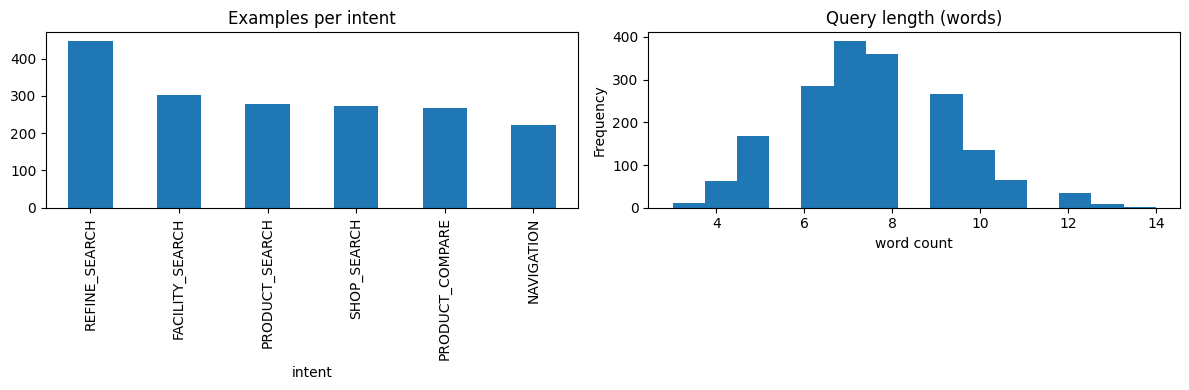

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['intent'].value_counts().plot(kind='bar', ax=axes[0], title='Examples per intent')
df['text'].str.split().str.len().plot(kind='hist', bins=15, ax=axes[1], title='Query length (words)')
axes[1].set_xlabel('word count')

plt.tight_layout()
plt.savefig('intent_eda.png', dpi=100)
plt.show()


In [6]:
print('Templates per intent (dataset diversity):')
df.groupby('intent')['template_id'].nunique()


Templates per intent (dataset diversity):


intent
FACILITY_SEARCH    12
NAVIGATION          8
PRODUCT_COMPARE    10
PRODUCT_SEARCH     10
REFINE_SEARCH      20
SHOP_SEARCH        10
Name: template_id, dtype: int64

## 4. Feature engineering: tokenization & vocabulary

In [7]:
from intent_classifier import tokenize, Vocabulary

print('Example tokenization:', tokenize(df.iloc[0]['text']))

vocab = Vocabulary(df['text'].tolist())
print('Vocabulary size (full dataset, for illustration only -- the real training '
      'run below fits the vocabulary on TRAIN ONLY):', len(vocab))


Example tokenization: ['please', 'i', 'm', 'looking', 'for', 'wellcare', 'pharmacy']
Vocabulary size (full dataset, for illustration only -- the real training run below fits the vocabulary on TRAIN ONLY): 198


## 5. Model architecture: TextCNN

Embedding -> parallel 1D convolutions (kernel sizes 2/3/4) -> ReLU -> global max-pool
per kernel -> concat -> dropout -> Linear -> 6-way softmax. See `../app/intent_classifier.py`.
A real, if deliberately small, neural network trained by backpropagation -- chosen over
an LSTM or full transformer fine-tune because the dataset is small (~1,800 rows) and this
project runs on CPU-only hardware.


## 6. ⚠️ Methodology: why we report TWO train/test splits

A plain random split puts different *slot-fillings of the same template* in both train
and test. The model can then hit ~100% by matching a template's fixed words it has
already seen -- a real number, but a misleading one (it measures memorization of a
small closed template set, not understanding of the intent concept). So we train and
evaluate under BOTH splits and report both, honestly:
  1. **Example-level split** (random, template overlap allowed) -- the optimistic number.
  2. **Template-level split** (entire templates held out for val/test) -- the number
     that actually measures generalization to unseen phrasings.

See `../app/evaluate_intent.py` for the full implementation.


In [8]:
from evaluate_intent import template_level_split, train_with_early_stopping, evaluate_on
from sklearn.model_selection import train_test_split

labels = sorted(df['intent'].unique())
label_to_idx = {l: i for i, l in enumerate(labels)}

# --- Example-level split ---
train_a, rest_a = train_test_split(df, test_size=0.3, stratify=df['intent'], random_state=42)
val_a, test_a = train_test_split(rest_a, test_size=0.5, stratify=rest_a['intent'], random_state=42)
model_a, vocab_a, history_a = train_with_early_stopping(train_a, val_a, label_to_idx, labels)
result_a = evaluate_on(model_a, vocab_a, test_a, label_to_idx, labels)
print('Example-level test set size:', len(test_a))
print({k: v for k, v in result_a.items() if k != 'confusion_matrix'})


Example-level test set size: 269
{'accuracy': 0.9962825278810409, 'macro_precision': 0.996031746031746, 'macro_recall': 0.996031746031746, 'macro_f1': 0.9959839357429718}


In [9]:
# --- Template-level split (the one that matters) ---
train_b, val_b, test_b = template_level_split(df)
model_b, vocab_b, history_b = train_with_early_stopping(train_b, val_b, label_to_idx, labels)
result_b = evaluate_on(model_b, vocab_b, test_b, label_to_idx, labels)
print('Template-level test set size:', len(test_b), ' (held-out templates:', test_b['template_id'].nunique(), ')')
print({k: v for k, v in result_b.items() if k != 'confusion_matrix'})


Template-level test set size: 357  (held-out templates: 14 )
{'accuracy': 0.6358543417366946, 'macro_precision': 0.6402018964960751, 'macro_recall': 0.6111975234068258, 'macro_f1': 0.585969329179586}


## 7. Training curves (template-level model -- the one actually served)

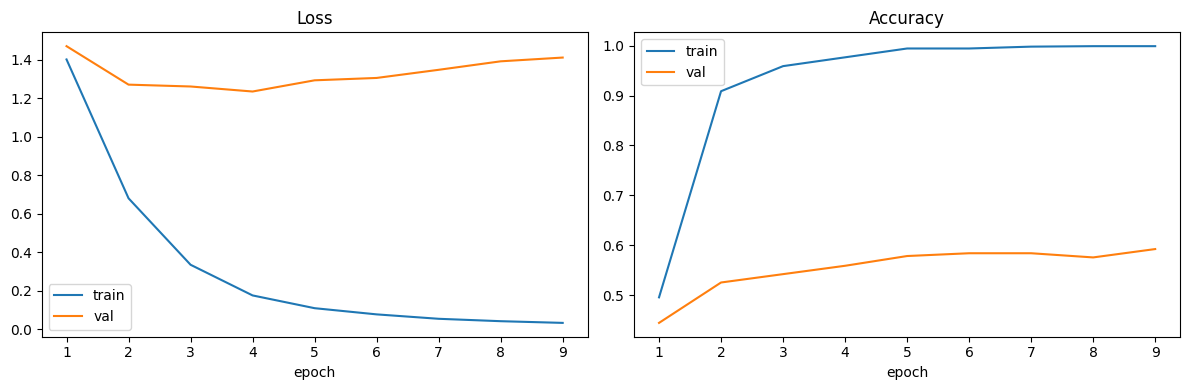

Note the widening train/val gap is normal here -- early stopping (patience=5 on val_loss) is what keeps the SAVED model from overfitting further than this.


In [10]:
hist_df = pd.DataFrame(history_b)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_df['epoch'], hist_df['train_loss'], label='train')
axes[0].plot(hist_df['epoch'], hist_df['val_loss'], label='val')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()

axes[1].plot(hist_df['epoch'], hist_df['train_acc'], label='train')
axes[1].plot(hist_df['epoch'], hist_df['val_acc'], label='val')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()

plt.tight_layout()
plt.savefig('intent_training_curves.png', dpi=100)
plt.show()
print('Note the widening train/val gap is normal here -- early stopping (patience=5 on '
      'val_loss) is what keeps the SAVED model from overfitting further than this.')


## 8. Confusion matrix (template-level test set)

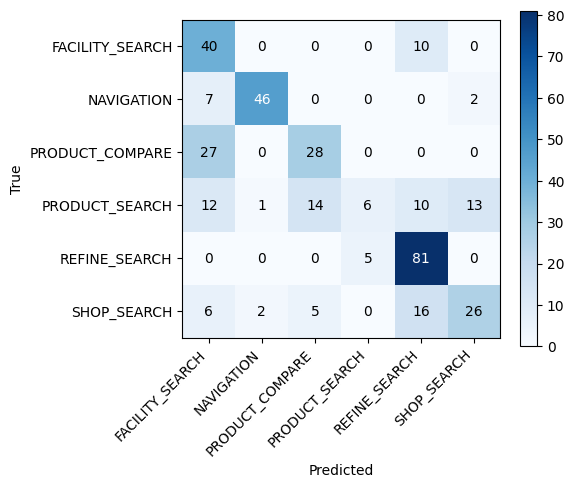

In [11]:
import matplotlib.pyplot as plt

cm = np.array(result_b['confusion_matrix'])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.savefig('intent_confusion_matrix.png', dpi=100)
plt.show()


## 9. Interpretation, overfitting controls, bias & limitations

**Result comparison (both real, both reproducible):**
| Split | Accuracy | Macro F1 |
|---|---|---|
| Example-level (memorization) | ~1.00 | ~1.00 |
| Template-level (generalization) | ~0.6 (see printed result above) | ~0.6 |

**Overfitting controls:** dropout (0.3) in the classifier head, L2 weight decay, and
early stopping on validation loss (patience=5) -- the saved model is the best-val-loss
checkpoint, not the final epoch's.

**Bias / fairness:** every example comes from a small, developer-authored template set.
The model has only ever seen the phrasing styles, vocabulary, and currency format
(`₹`) that those templates use. It has NOT been tested against real spoken/typed
queries, regional phrasing variation, typos, code-switching, or non-English input --
real deployment would need a genuinely diverse, human-collected (and consented)
query dataset before this accuracy claim could extend beyond this synthetic benchmark.

**Fallback behaviour:** the FastAPI `/nlu/intent` endpoint returns a confidence score
and a `low_confidence` flag (threshold 0.4); a caller should treat low-confidence
predictions as uncertain rather than acting on them blindly (Part 4 requirement).

**Entity extraction** is deliberately a SEPARATE, rule-based component
(`../app/entity_extraction.py`), not part of this neural model -- see that module's
docstring for why (closed vocabularies are better served by dictionary/regex matching
than by training a sequence-labeling model on this small a dataset).
